<a href="https://colab.research.google.com/github/nguyendangcole/colab-demo/blob/main/demo_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🚀 Google Colab & Git Workflow Demo (Version 2.0)
Notebook được cập nhật từ **Antigravity IDE** với tính năng kiểm tra GPU Pro, đo hiệu năng ma trận và mô phỏng lưu Checkpoint.

### 1. Kiểm tra phần cứng: GPU Colab Pro (CUDA Detection)
> **Mẹo:** Nếu hiện `CUDA Available: False`, hãy vào menu **Runtime** (Thời gian chạy) -> **Change runtime type** (Thay đổi loại thời gian chạy) -> Chọn **T4 GPU** hoặc **A100 GPU**.

In [3]:
import torch

print(f"🔥 PyTorch Version: {torch.__version__}")
cuda_available = torch.cuda.is_available()
print(f"⚡ CUDA Available: {cuda_available}")

if cuda_available:
    device_name = torch.cuda.get_device_name(0)
    vram = torch.cuda.get_device_properties(0).total_memory / (1024**3)
    print(f"🎯 Đang sử dụng GPU: {device_name}")
    print(f"💾 Tổng dung lượng VRAM: {vram:.2f} GB")
else:
    print("⚠️ Đang chạy trên CPU! Hãy chuyển sang GPU trong mục Runtime để tăng tốc tối đa.")

🔥 PyTorch Version: 2.11.0+cpu
⚡ CUDA Available: False
⚠️ Đang chạy trên CPU! Hãy chuyển sang GPU trong mục Runtime để tăng tốc tối đa.


### 2. Thử nghiệm tốc độ: Nhân ma trận 6000x6000

In [4]:
import time

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Đang chạy benchmark trên thiết bị: {device}")

size = 6000
x = torch.randn(size, size, device=device)
y = torch.randn(size, size, device=device)

# Warm up
_ = torch.matmul(x, y)
if torch.cuda.is_available():
    torch.cuda.synchronize()

# Đo thời gian thực
start_time = time.time()
for i in range(5):
    z = torch.matmul(x, y)
if torch.cuda.is_available():
    torch.cuda.synchronize()
elapsed = time.time() - start_time

print(f"⏱️ Thời gian nhân 5 lần ma trận ({size}x{size}): {elapsed:.4f} giây!")

Đang chạy benchmark trên thiết bị: cpu
⏱️ Thời gian nhân 5 lần ma trận (6000x6000): 36.9132 giây!


### 3. Huấn luyện mô phỏng & Vẽ biểu đồ trực quan

Bắt đầu training mô phỏng qua 10 epochs...
Epoch [01/10] -> Train Loss: 1.0041 | Val Loss: 1.1626 | LR: 0.009755
Epoch [02/10] -> Train Loss: 0.6594 | Val Loss: 0.7259 | LR: 0.009045
Epoch [03/10] -> Train Loss: 0.4725 | Val Loss: 0.5338 | LR: 0.007939
Epoch [04/10] -> Train Loss: 0.3657 | Val Loss: 0.4878 | LR: 0.006545
Epoch [05/10] -> Train Loss: 0.3084 | Val Loss: 0.3721 | LR: 0.005000
Epoch [06/10] -> Train Loss: 0.2880 | Val Loss: 0.4011 | LR: 0.003455
Epoch [07/10] -> Train Loss: 0.2486 | Val Loss: 0.3084 | LR: 0.002061
Epoch [08/10] -> Train Loss: 0.2451 | Val Loss: 0.2351 | LR: 0.000955
Epoch [09/10] -> Train Loss: 0.2084 | Val Loss: 0.2669 | LR: 0.000245
Epoch [10/10] -> Train Loss: 0.1924 | Val Loss: 0.2203 | LR: 0.000000


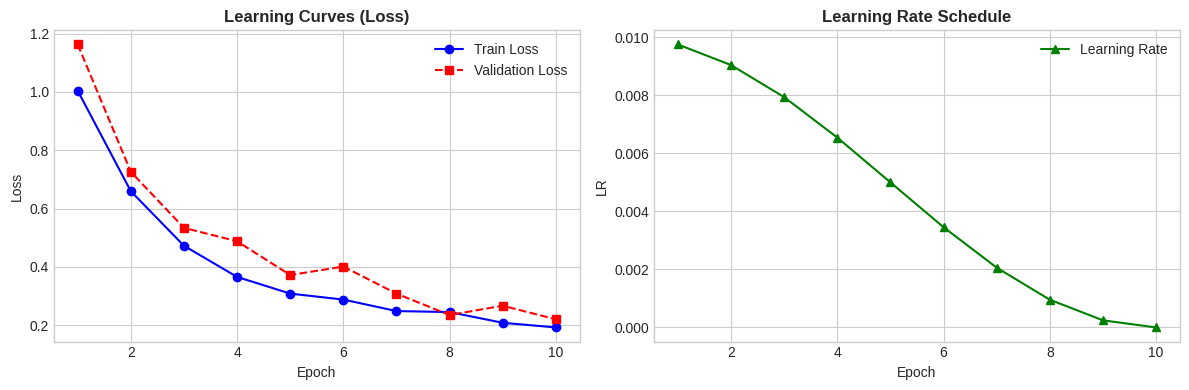

In [5]:
import numpy as np
import matplotlib.pyplot as plt

epochs = 10
print(f"Bắt đầu training mô phỏng qua {epochs} epochs...")

train_loss = []
val_loss = []
learning_rates = []

base_lr = 0.01
for epoch in range(1, epochs + 1):
    # Giả lập loss và learning rate giảm theo cosine annealing
    lr = base_lr * (0.5 * (1 + np.cos(np.pi * epoch / epochs)))
    t_loss = 1.0 / (epoch**0.7) + np.random.normal(0, 0.02)
    v_loss = 1.1 / (epoch**0.65) + np.random.normal(0, 0.03)

    train_loss.append(t_loss)
    val_loss.append(v_loss)
    learning_rates.append(lr)

    print(f"Epoch [{epoch:02d}/{epochs:02d}] -> Train Loss: {t_loss:.4f} | Val Loss: {v_loss:.4f} | LR: {lr:.6f}")
    time.sleep(0.3)

# Vẽ 2 biểu đồ so sánh: Loss curves & Learning Rate schedule
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(range(1, epochs + 1), train_loss, 'b-o', label='Train Loss')
ax1.plot(range(1, epochs + 1), val_loss, 'r--s', label='Validation Loss')
ax1.set_title('Learning Curves (Loss)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(True)

ax2.plot(range(1, epochs + 1), learning_rates, 'g-^', label='Learning Rate')
ax2.set_title('Learning Rate Schedule', fontsize=12, fontweight='bold')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('LR')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

### 4. Giả lập lưu Checkpoint bền vững

In [6]:
import os

# Tạo thư mục checkpoint cục bộ
ckpt_dir = "./saved_checkpoints"
os.makedirs(ckpt_dir, exist_ok=True)

dummy_weights = {"epoch": epochs, "best_loss": min(val_loss), "status": "Trained successfully!"}
ckpt_path = os.path.join(ckpt_dir, "best_model_demo.pt")
torch.save(dummy_weights, ckpt_path)

print(f"✅ Đã lưu checkpoint mẫu vào: {ckpt_path}")
print(f"📦 Kích thước file: {os.path.getsize(ckpt_path)} bytes")
print("💡 Khi làm project thật với Drive, bạn chỉ cần thay đường dẫn thành: /content/drive/MyDrive/...")

✅ Đã lưu checkpoint mẫu vào: ./saved_checkpoints/best_model_demo.pt
📦 Kích thước file: 1373 bytes
💡 Khi làm project thật với Drive, bạn chỉ cần thay đường dẫn thành: /content/drive/MyDrive/...
